##0. Previous work : Import the required libraries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import sympy as sp

## 1. One-dimensional case

In this section we study the function

$$f(x) = x^3 - 2x + 2, \qquad x \in \mathbb{R}$$

Our goal is to find its critical points analytically, and to determine whether each of them is a local minimum or a local maximum.

### 1.1. Plotting f(x)

We first plot $f(x)$ on the range $x \in [-2, 2]$ to get a visual idea of where the function might have a minimum and/or a maximum.

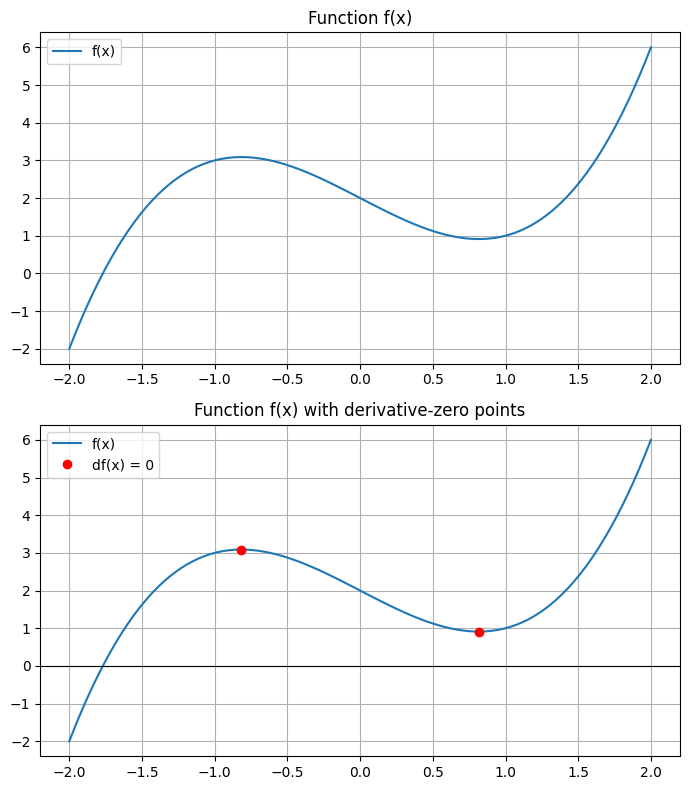

In [ ]:
def f(x):
    return x**3 - 2 * x + 2


x_values = np.linspace(-2, 2, 100)
y_values = f(x_values)

# Compute the points where the derivative is zero
x_derivative_cero = np.roots([3, 0, -2])
y_derivative_cero = f(x_derivative_cero)


fig, (ax_top, ax_bottom) = plt.subplots(2, 1, figsize=(7, 8))


ax_top.plot(x_values, y_values, label="f(x)")
ax_top.set_title("Function f(x)")
ax_top.grid()
ax_top.legend()

ax_bottom.plot(x_values, y_values, label="f(x)")
ax_bottom.plot(
    x_derivative_cero,
    y_derivative_cero,
    "ro",
    label="df(x) = 0"
)
ax_bottom.set_title("Function f(x) with derivative-zero points")
ax_bottom.axhline(0, color="black", linewidth=0.8)
ax_bottom.grid()
ax_bottom.legend()

plt.tight_layout()
plt.show()



### 1.2. Analytical critical points

A critical point $x^*$ must satisfy $f'(x^*) = 0$. For our function,

$$f'(x) = 3x^2 - 2$$

Setting $f'(x) = 0$:

$$3x^2 - 2 = 0 \;\Longleftrightarrow\; x^2 = \frac{2}{3} \;\Longleftrightarrow\; x = \pm\sqrt{\frac{2}{3}} \approx \pm 0.8165$$

So we obtain two critical points, $x_1^* \approx -0.8165$ and $x_2^* \approx 0.8165$, which matches the two turning points we identified visually in the plot above.

### 1.3. Classifying the critical points

To classify each critical point $x^*$ we use the second-order Taylor expansion around it:

$$f(x^* + d) \approx f(x^*) + d\,f'(x^*) + \tfrac{1}{2} d^2 f''(x^*)$$

Since $f'(x^*) = 0$ at a critical point, the local behaviour of $f$ around $x^*$ is entirely governed by the sign of $f''(x^*)$:

- if $f''(x^*) > 0$, the quadratic term is positive for any $d \neq 0$, so $f$ increases in every direction around $x^*$ → **local minimum**.
- if $f''(x^*) < 0$, the quadratic term is negative for any $d \neq 0$, so $f$ decreases in every direction around $x^*$ → **local maximum**.

For our function, $f''(x) = 6x$.

In [ ]:
# Compute the points where the derivative is zero
def d2f(x):
  return 6*x

for value in x_derivative_cero:
  if value > 0:
    print(f'The point {value} is a minimum')
  else:
    print(f'The point {value} is a maximum')

The point -0.816496580927726 is a maximum
The point 0.8164965809277259 is a minimum


### 1.4. Plotting the second derivative

Finally, we plot $f''(x) = 6x$ on the same range $x \in [-2, 2]$. Wherever $f''(x) > 0$, the function $f(x)$ is convex, wherever $f''(x) < 0$, it is concave.

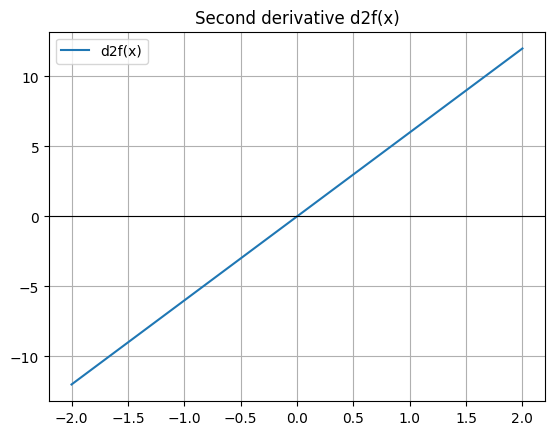

In [ ]:
x_second_derivative_values = np.linspace(-2, 2, 100)
y_second_derivative_values = d2f(x_second_derivative_values)


plt.plot(x_second_derivative_values, y_second_derivative_values, label="d2f(x)")
plt.title("Second derivative d2f(x)")
plt.axhline(0, color="black", linewidth=0.8)
plt.grid()
plt.legend()
plt.show()

In summary, the cubic $f(x) = x^3 - 2x + 2$ has two critical points, $x^* \approx \pm 0.8165$, obtained by solving $f'(x)=0$. Evaluating the sign of $f''(x^*)$ at each of them shows that $x^*\approx -0.8165$ is a local maximum and $x^*\approx 0.8165$ is a local minimum, which agrees with both the shape of $f(x)$ and the sign pattern of $f''(x)$ around each point.

## 2. Two-dimensional case

### 2.1. A simple two-dimensional function

We now move from the one-dimensional case to functions of two variables, $\mathbf{x} = (x_1, x_2)^T \in \mathbb{R}^2$. We start with the following function:

$$f(x_1, x_2) = x_1^2 + x_2^2$$

#### 2.1.1. Plotting f(x1, x2)

We plot the function as a 3D surface over the range $x_1, x_2 \in [-5, 5]$, in order to visually confirm that it has a single minimum at $(x_1, x_2) = (0, 0)$.

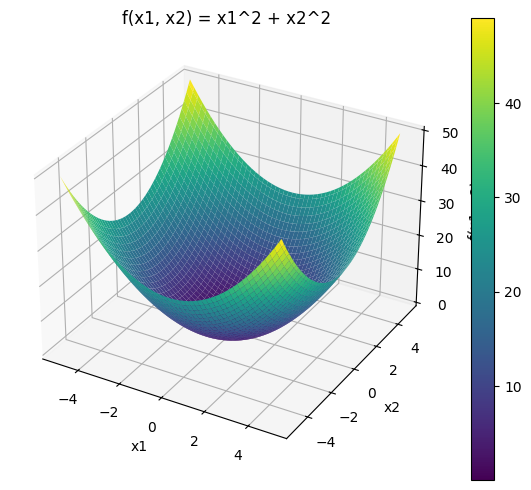

In [ ]:
x1 = np.linspace(-5, 5, 100)
x2 = np.linspace(-5, 5, 100)
X1, X2 = np.meshgrid(x1, x2)

Z = X1**2 + X2**2

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(projection="3d")
surf = ax.plot_surface(X1, X2, Z, cmap="viridis")

ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("f(x1, x2)")
ax.set_title("f(x1, x2) = x1^2 + x2^2")
fig.colorbar(surf)
plt.show()

#### 2.1.2. Gradient and critical point

The gradient of $f(x_1, x_2) = x_1^2 + x_2^2$ is

$$\nabla f(x_1, x_2) = \begin{pmatrix} \dfrac{\partial f}{\partial x_1} \\[4pt] \dfrac{\partial f}{\partial x_2} \end{pmatrix} = \begin{pmatrix} 2x_1 \\ 2x_2 \end{pmatrix}$$

Setting $\nabla f(\mathbf{x}^*) = \mathbf{0}$ gives $2x_1^* = 0$ and $2x_2^* = 0$, so the only critical point is

$$\mathbf{x}^* = (0, 0)$$

which matches the point we identified visually in 2.1.1. We verify this symbolically below.

In [ ]:
x1, x2 = sp.symbols("x1 x2")

f = x1**2 + x2**2

df_dx1 = sp.diff(f, x1)
df_dx2 = sp.diff(f, x2)

print("Gradient:")
print("df/dx1 =", df_dx1)
print("df/dx2 =", df_dx2)

critical_point = sp.solve([df_dx1, df_dx2], [x1, x2])
print("\nCritical point x*:", critical_point)

Gradient:
df/dx1 = 2*x1
df/dx2 = 2*x2

Critical point x*: {x1: 0, x2: 0}


#### 2.1.3. Hessian matrix and classification

To classify $\mathbf{x}^* = (0,0)$, we use the 2nd order Taylor expansion around it:

$$f(\mathbf{x}^* + \mathbf{d}) \approx f(\mathbf{x}^*) + \mathbf{d}^T \nabla f(\mathbf{x}^*) + \frac{1}{2}\, \mathbf{d}^T \nabla^2 f(\mathbf{x}^*)\, \mathbf{d}$$

At a critical point $\nabla f(\mathbf{x}^*) = \mathbf{0}$, so everything depends on the quadratic term, i.e. on the Hessian $\nabla^2 f(\mathbf{x}^*)$:

- Hessian **positive definite** (all eigenvalues > 0) → **minimum**
- Hessian **negative definite** (all eigenvalues < 0) → **maximum**

Let's compute the Hessian and check its eigenvalues:.

In [ ]:
H = sp.hessian(f, [x1, x2])
print("Hessian matrix:")
sp.pprint(H)

eigenvalues = H.eigenvals()
print("\nEigenvalues of the Hessian:", eigenvalues)

Hessian matrix:
⎡2  0⎤
⎢    ⎥
⎣0  2⎦

Eigenvalues of the Hessian: {2: 2}


The Hessian is

$$\nabla^2 f(\mathbf{x}^*) = \begin{pmatrix} 2 & 0 \\ 0 & 2 \end{pmatrix}$$

with both eigenvalues equal to $2 > 0$. Since the Hessian is positive definite (all eigenvalues strictly positive), $\mathbf{x}^* = (0,0)$ is a **minimum** of $f(x_1, x_2) = x_1^2 + x_2^2$, as we already saw in the 3D plot.

#### 2.1.4. What if the eigenvalues have different signs (or are zero)?

So far we've seen a case where both eigenvalues of the Hessian are positive, giving a minimum. Let's now look at what happens in the other cases:

$$f_A(x_1, x_2) = -x_1^2 - x_2^2 \qquad f_B(x_1, x_2) = x_1^2 - x_2^2 \qquad f_C(x_1, x_2) = x_1^2$$

For each one, we find the point where the gradient is zero, compute the Hessian and its eigenvalues, and use them to decide whether that point is a minimum, a maximum, or something else.

##### (a) Plots and the point where the gradient is zero

We plot the three functions and compute, for each one, the point $\mathbf{x}^*$ where $\nabla f(\mathbf{x}^*) = \mathbf{0}$.

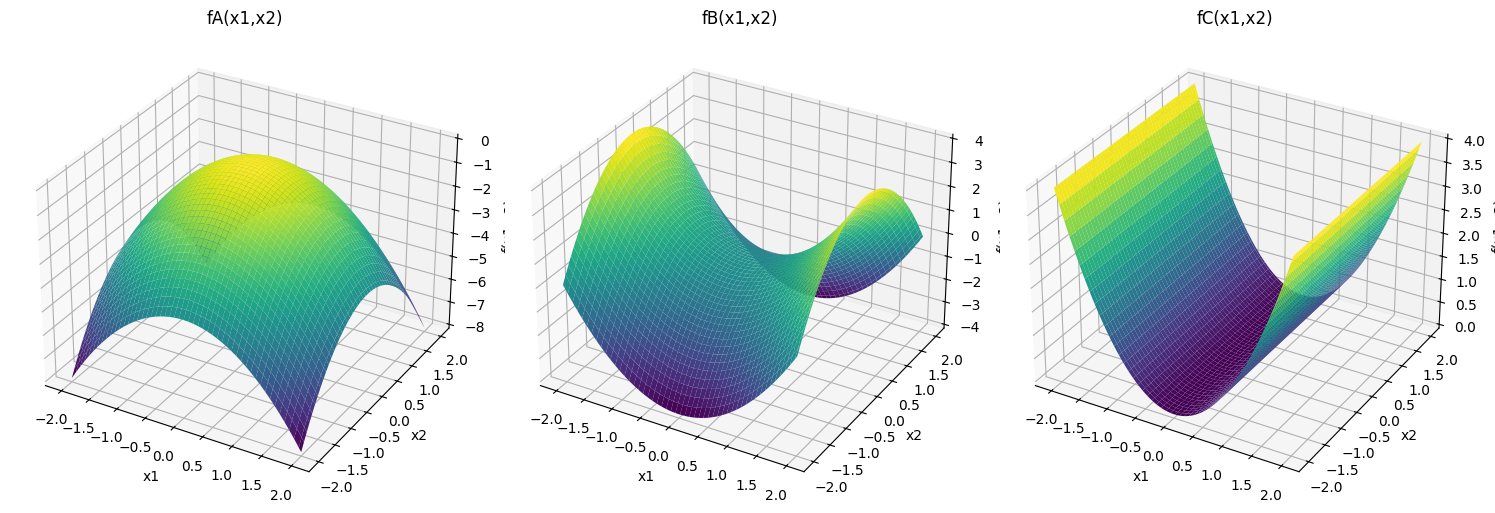

In [ ]:
x1 = np.linspace(-2, 2, 100)
x2 = np.linspace(-2, 2, 100)
X1, X2 = np.meshgrid(x1, x2)

fA = -X1**2 - X2**2
fB = X1**2 - X2**2
fC = X1**2

fig = plt.figure(figsize=(15, 5))

for i, (Z, title) in enumerate(zip([fA, fB, fC], ["fA(x1,x2)", "fB(x1,x2)", "fC(x1,x2)"]), start=1):
    ax = fig.add_subplot(1, 3, i, projection="3d")
    surf = ax.plot_surface(X1, X2, Z, cmap="viridis")
    ax.set_title(title)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_zlabel("f(x1,x2)")

plt.tight_layout()
plt.show()

##### (b) Hessian Matrix and Eigenvalues Analysis

Next, we will determine the critical points for each function, the points where their respective gradients are equal to zero. We will then compute the Hessian matrix and its eigenvalues to analyze the local behavior of these points and classify them as local minima, local maxima, or saddle points.

In [ ]:
x1, x2 = sp.symbols("x1 x2")

functions = {
    "fA": -x1**2 - x2**2,
    "fB": x1**2 - x2**2,
    "fC": x1**2,
}

for name, expr in functions.items():
    grad = [sp.diff(expr, v) for v in (x1, x2)]
    crit = sp.solve(grad, (x1, x2), dict=True)
    H = sp.hessian(expr, (x1, x2))
    eig = list(H.eigenvals().keys())

    print(f"--- {name}(x1, x2) = {expr} ---")
    print("Gradient:", grad)
    print("Critical point(s):", crit)
    print("Hessian:", H.tolist())
    print("Eigenvalues:", eig)
    print()

--- fA(x1, x2) = -x1**2 - x2**2 ---
Gradient: [-2*x1, -2*x2]
Critical point(s): [{x1: 0, x2: 0}]
Hessian: [[-2, 0], [0, -2]]
Eigenvalues: [-2]

--- fB(x1, x2) = x1**2 - x2**2 ---
Gradient: [2*x1, -2*x2]
Critical point(s): [{x1: 0, x2: 0}]
Hessian: [[2, 0], [0, -2]]
Eigenvalues: [2, -2]

--- fC(x1, x2) = x1**2 ---
Gradient: [2*x1, 0]
Critical point(s): [{x1: 0}]
Hessian: [[2, 0], [0, 0]]
Eigenvalues: [2, 0]



Based on the eigenvalues computed by the code, we can classify the critical point at $\mathbf{x}^* = (0, 0)$ for each function:

1. For $f_A(\mathbf{x}) = -x_1^2 - x_2^2$:
   The eigenvalues of the Hessian are both negative ($-2, -2$). Because they are strictly negative, the critical point is a **maximum**.
   
2. For $f_B(\mathbf{x}) = x_1^2 - x_2^2$:
   The eigenvalues of the Hessian have mixed signs ($2, -2$). Because they are mixed, the critical point is a **saddle point**.
   
3. For $f_C(\mathbf{x}) = x_1^2$:
   The eigenvalues are $2$ and $0$. Because they are non-negative and one is zero, the Hessian is positive semi-definite. The point $(0, 0)$ belongs to a whole line of **minima** (a valley) running along the $x_2$-axis.

## 2.2. A two-dimensional function with multiple minima

We now study a function with several minima, maxima and saddle points:

$$f(x_1, x_2) = x_1^2\left(4 - 2.1\,x_1^2 + \frac{1}{3}x_1^4\right) + x_1 x_2 + x_2^2\left(-4 + 4x_2^2\right)$$

#### 2.2.1. Plotting the function

We plot $f$ on $x_1 \in [-2, 2]$ and $x_2 \in [-1, 1]$ with a step of 0.1.

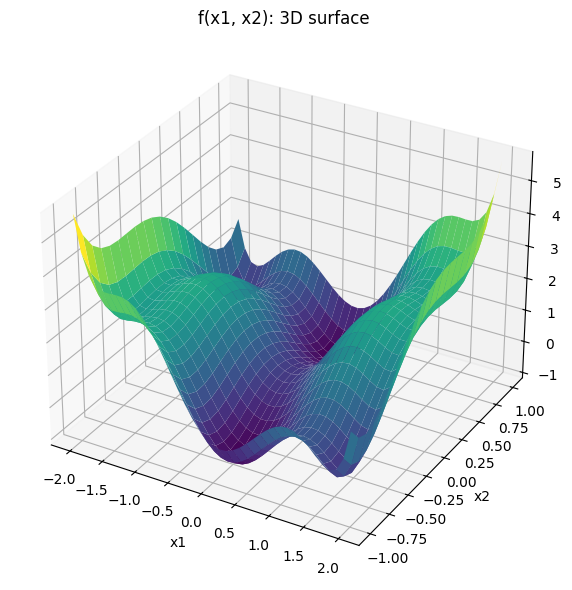

In [ ]:
def f_multi(x1, x2):
    return x1**2 * (4 - 2.1 * x1**2 + (1/3) * x1**4) + x1 * x2 + x2**2 * (-4 + 4 * x2**2)


x1 = np.linspace(-2, 2, 41)   # step 0.1
x2 = np.linspace(-1, 1, 21)   # step 0.1
X1, X2 = np.meshgrid(x1, x2)
Z = f_multi(X1, X2)

fig = plt.figure(figsize=(14, 6))

# 3D surface
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
surf = ax1.plot_surface(X1, X2, Z, cmap="viridis")
ax1.set_xlabel("x1")
ax1.set_ylabel("x2")
ax1.set_zlabel("f(x1, x2)")
ax1.set_title("f(x1, x2): 3D surface")

plt.tight_layout()
plt.show()

#### 2.2.2. Gradient

$$f(x_1, x_2) = 4x_1^2 - 2.1\,x_1^4 + \frac{1}{3}x_1^6 + x_1 x_2 - 4x_2^2 + 4x_2^4$$

Differentiating with respect to each variable:

$$\nabla f(x_1, x_2) = \begin{pmatrix} \dfrac{\partial f}{\partial x_1} \\[4pt] \dfrac{\partial f}{\partial x_2} \end{pmatrix} = \begin{pmatrix} 8x_1 - 8.4\,x_1^3 + 2x_1^5 + x_2 \\[4pt] x_1 - 8x_2 + 16x_2^3 \end{pmatrix}$$

In [ ]:
x1_sym, x2_sym = sp.symbols("x1 x2")

f_multi_expr = (
    x1_sym**2 * (4 - 2.1 * x1_sym**2 + sp.Rational(1, 3) * x1_sym**4)
    + x1_sym * x2_sym
    + x2_sym**2 * (-4 + 4 * x2_sym**2)
)

df_dx1 = sp.expand(sp.diff(f_multi_expr, x1_sym))
df_dx2 = sp.expand(sp.diff(f_multi_expr, x2_sym))

print("df/dx1 =", df_dx1)
print("df/dx2 =", df_dx2)

def grad_f_multi(x1, x2):
    df_dx1 = 8 * x1 - 8.4 * x1**3 + 2 * x1**5 + x2
    df_dx2 = x1 - 8 * x2 + 16 * x2**3
    return df_dx1, df_dx2

df/dx1 = 2*x1**5 - 8.4*x1**3 + 8*x1 + x2
df/dx2 = x1 + 16*x2**3 - 8*x2


#### 2.2.3. Numerical approximation of the points where $\nabla f(\mathbf{x}^*) = 0$

Solving $\nabla f = 0$ by hand is not easy, so we approximate the solutions numerically.

##### (a) Evaluating $\|\nabla f(\mathbf{x})\|^2$ on a fine grid

In [ ]:
step = 0.005
x1 = np.arange(-2, 2 + step / 2, step)
x2 = np.arange(-1, 1 + step / 2, step)
X1, X2 = np.meshgrid(x1, x2)

G1, G2 = grad_f_multi(X1, X2)
grad_norm2 = G1**2 + G2**2   # matrix of ||grad f(x)||^2

print("Grid shape (rows = x2, columns = x1):", grad_norm2.shape)

Grid shape (rows = x2, columns = x1): (401, 801)


##### (b) Brute-force search of candidate points

We look for the grid points where $\|\nabla f(\mathbf{x})\|^2$ is strictly smaller than at each of its 8 neighbours.

In [ ]:
center = grad_norm2[1:-1, 1:-1]          # interior points only
is_candidate = np.ones_like(center, dtype=bool)

# Compare each interior point with its 8 neighbours
for di in (-1, 0, 1):
    for dj in (-1, 0, 1):
        if di == 0 and dj == 0:
            continue
        neighbour = grad_norm2[1 + di : grad_norm2.shape[0] - 1 + di,
                               1 + dj : grad_norm2.shape[1] - 1 + dj]
        is_candidate &= center < neighbour

rows, cols = np.where(is_candidate)
candidates = [(X1[i + 1, j + 1], X2[i + 1, j + 1], grad_norm2[i + 1, j + 1])
              for i, j in zip(rows, cols)]

print("Number of candidate points found:", len(candidates))

Number of candidate points found: 15


##### (c) Obtained points and value of $\|\nabla f(\mathbf{x})\|^2$

These are the candidate points $\tilde{\mathbf{x}}$ and the value of $\|\nabla f\|^2$ at each of them. Since we work on a grid, the gradient is very small but not exactly zero (except at the origin, which is a grid point).

      x1       x2     ||grad f||^2
  -1.705    0.795         1.43e-03
  -1.640   -0.230         6.75e-04
  -1.605   -0.570         4.16e-04
  -1.295   -0.605         4.54e-05
  -1.230   -0.160         2.42e-04
  -1.110    0.770         1.26e-03
  -0.090    0.715         1.48e-03
  -0.000    0.000         1.18e-25
   0.090   -0.715         1.48e-03
   1.110   -0.770         1.26e-03
   1.230    0.160         2.42e-04
   1.295    0.605         4.54e-05
   1.605    0.570         4.16e-04
   1.640    0.230         6.75e-04
   1.705   -0.795         1.43e-03


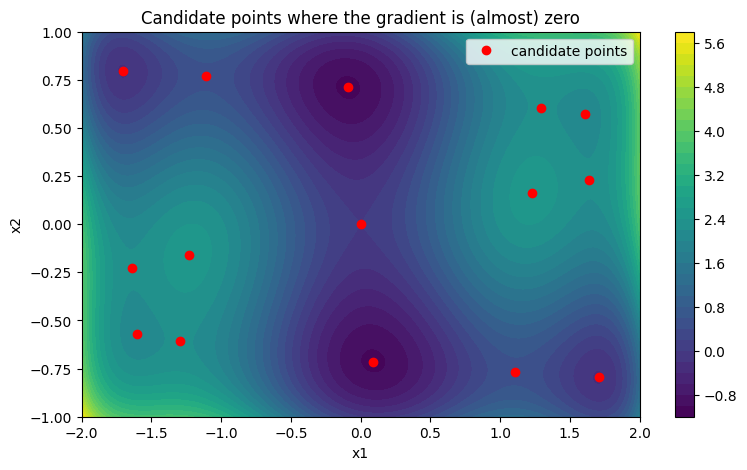

In [ ]:
candidates = sorted(candidates, key=lambda c: (c[0], c[1]))

print(f"{'x1':>8} {'x2':>8} {'||grad f||^2':>16}")
for x1c, x2c, val in candidates:
    print(f"{x1c:8.3f} {x2c:8.3f} {val:16.2e}")

# Visual check: candidates over the contour plot
Z_fine = f_multi(X1, X2)
plt.figure(figsize=(9, 5))
cs = plt.contourf(X1, X2, Z_fine, levels=40, cmap="viridis")
plt.colorbar(cs)
plt.plot([c[0] for c in candidates], [c[1] for c in candidates], "ro", label="candidate points")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Candidate points where the gradient is (almost) zero")
plt.legend()
plt.show()

#### 2.2.4. Hessian and classification of the candidate points

The gradient is (almost) zero at all the candidates $\tilde{\mathbf{x}}$, but this doesn't tell us what kind of point each one is, for that we use the Hessian.

##### Analytical Hessian

The Hessian for every point $(x_1, x_2)^T\in \mathbb{R}$:

$$\nabla^2 f(x_1, x_2) = \begin{pmatrix} \dfrac{\partial^2 f}{\partial x_1^2} & \dfrac{\partial^2 f}{\partial x_1 \partial x_2} \\[8pt] \dfrac{\partial^2 f}{\partial x_2 \partial x_1} & \dfrac{\partial^2 f}{\partial x_2^2} \end{pmatrix} = \begin{pmatrix} 8 - 25.2\,x_1^2 + 10\,x_1^4 & 1 \\[4pt] 1 & -8 + 48\,x_2^2 \end{pmatrix}$$

     x1      x2            eigenvalues   type              f(x)
 -1.705   0.795        [18.955 22.633]   minimum        -0.2154
 -1.640  -0.230        [12.617 -5.516]   saddle point    2.2294
 -1.605  -0.570          [9.881 7.158]   minimum         2.1043
 -1.295  -0.605        [-6.2    9.633]   saddle point    2.2295
 -1.230  -0.160        [-8.031 -5.977]   maximum         2.4963
 -1.110   0.770        [-7.903 20.494]   saddle point    0.5437
 -0.090   0.715        [ 7.684 16.652]   minimum        -1.0316
 -0.000   0.000        [ 8.062 -8.062]   saddle point    0.0000
  0.090  -0.715        [ 7.684 16.652]   minimum        -1.0316
  1.110  -0.770        [-7.903 20.494]   saddle point    0.5437
  1.230   0.160        [-8.031 -5.977]   maximum         2.4963
  1.295   0.605        [-6.2    9.633]   saddle point    2.2295
  1.605   0.570          [9.881 7.158]   minimum         2.1043
  1.640   0.230        [12.617 -5.516]   saddle point    2.2294
  1.705  -0.795        [18.955 22.633]  

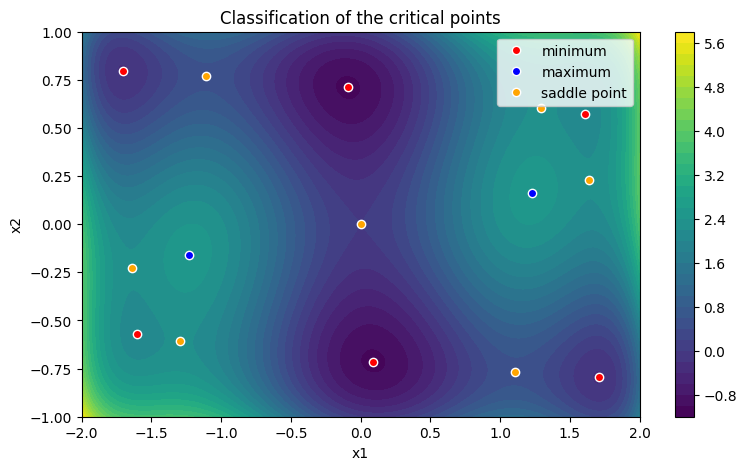

In [ ]:
H_multi = sp.hessian(f_multi_expr, (x1_sym, x2_sym))


def hessian_f_multi(x1, x2):
    d2f_dx1x1 = 8 - 25.2 * x1**2 + 10 * x1**4
    d2f_dx1x2 = 1.0
    d2f_dx2x2 = -8 + 48 * x2**2
    return np.array([[d2f_dx1x1, d2f_dx1x2],
                     [d2f_dx1x2, d2f_dx2x2]])

results = []   # (x1, x2, eigenvalues, type, f value)

for x1c, x2c, val in candidates:
    eig = np.linalg.eigvals(hessian_f_multi(x1c, x2c))

    if np.all(eig > 0):
        point_type = "minimum"
    elif np.all(eig < 0):
        point_type = "maximum"
    else:
        point_type = "saddle point"

    results.append((x1c, x2c, eig, point_type, f_multi(x1c, x2c)))

print(f"{'x1':>7} {'x2':>7}   {'eigenvalues':>20}   {'type':<13} {'f(x)':>8}")
for x1c, x2c, eig, point_type, f_val in results:
    print(f"{x1c:7.3f} {x2c:7.3f}   {str(eig.round(3)):>20}   {point_type:<13} {f_val:8.4f}")

n_min = sum(r[3] == "minimum" for r in results)
n_max = sum(r[3] == "maximum" for r in results)
n_saddle = sum(r[3] == "saddle point" for r in results)
print(f"\nMinima: {n_min} | Maxima: {n_max} | Saddle points: {n_saddle}")

# Visual summary: candidate points coloured by type, over the contour plot
Z_fine = f_multi(X1, X2)
colors = {"minimum": "red", "maximum": "blue", "saddle point": "orange"}

plt.figure(figsize=(9, 5))
cs = plt.contourf(X1, X2, Z_fine, levels=40, cmap="viridis")
plt.colorbar(cs)

for point_type, color in colors.items():
    pts = [(r[0], r[1]) for r in results if r[3] == point_type]
    plt.plot([p[0] for p in pts], [p[1] for p in pts], "o", color=color,
             markeredgecolor="white", label=point_type)

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Classification of the critical points")
plt.legend()
plt.show()

##### Conclusions

Of the 15 candidate points:

- **6 minima** (both eigenvalues positive, Hessian positive definite). The two deepest ones are at $\approx (-0.09, 0.715)$ and $\approx (0.09, -0.715)$, with $f \approx -1.03$: these are the **global minima**. The other four are local minima (around $(\pm 1.705, \mp 0.795)$ and $(\pm 1.605, \pm 0.570)$).
- **2 maxima** (both eigenvalues negative, Hessian negative definite), at $\approx \pm(1.23, 0.16)$.
- **7 saddle points** (one positive and one negative eigenvalue, Hessian indefinite), including the origin $(0,0)$.

The points come in symmetric pairs $(x_1, x_2)$ and $(-x_1, -x_2)$, as expected from $f(-x_1,-x_2) = f(x_1,x_2)$. Note that the origin is a candidate but **not** a minimum, even though it is where $\|\nabla f\|^2$ is smallest: it is a saddle point. This is why the gradient alone is not enough and the Hessian is needed.